# Support vector Machine


In [1]:
import pandas as pd  
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\Social_Network_Ads.csv')
df.head()

<>:1: SyntaxWarning: "\B" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\B"? A raw string is also an option.
<>:1: SyntaxWarning: "\B" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\B"? A raw string is also an option.
C:\Users\Snehal\AppData\Local\Temp\ipykernel_26164\423220243.py:1: SyntaxWarning: "\B" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\B"? A raw string is also an option.
  df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\Social_Network_Ads.csv')


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [3]:
# Check Dataset

df.shape

(400, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


In [5]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [7]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [8]:
X = df.iloc[:,2:4]
y = df.iloc[:,4]

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [10]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
# Import SVM

from sklearn.svm import SVC

In [12]:
# Create Model

model = SVC()

In [13]:
# Train Model

model.fit(X_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [14]:
# Prediction

y_pred = model.predict(X_test)

In [15]:
# Compare Actual and Prediction

result = pd.DataFrame({
    'Actual':y_test,
    'Predicted': y_pred
})
result.head()

,Actual,Predicted
209,0,1
280,1,1
33,0,0
210,1,1
93,0,0


In [17]:
# Accuracy

from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)



0.925

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[47  5]
 [ 1 27]]


In [19]:
# Classification Report

from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.90      0.94        52
           1       0.84      0.96      0.90        28

    accuracy                           0.93        80
   macro avg       0.91      0.93      0.92        80
weighted avg       0.93      0.93      0.93        80



In [20]:
# ROC AUC

from sklearn.metrics import roc_auc_score
print(roc_auc_score(y_test, y_pred))

0.9340659340659341


# Kernal Tricks in SVM

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

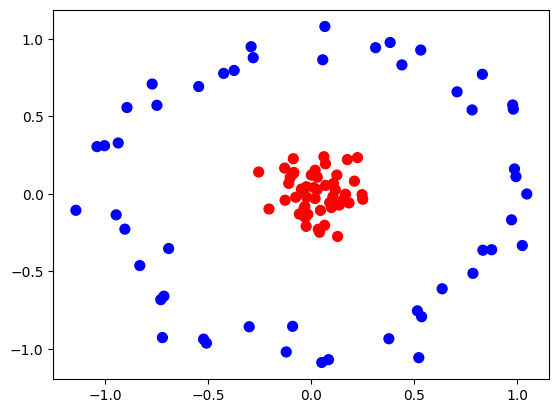

In [23]:
from sklearn.datasets._samples_generator import make_circles
X,y = make_circles(100, factor=.1, noise=.1)

plt.scatter(X[:,0], X[:,1],c=y, s=50, cmap='bwr')

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20)

In [26]:
classifier = SVC(kernel='linear')
classifier.fit(X_train,y_train.ravel())
y_pred = classifier.predict(X_test)

In [27]:
from sklearn.metrics import accuracy_score
accuracy_score (y_test, y_pred)

0.6

In [28]:
zero_one_colourmap = ListedColormap(('blue', 'red'))
def plot_decision_boundary(X, y, clf):
    X_set, y_set = X, y
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, 
                                 stop = X_set[:, 0].max() + 1, 
                                 step = 0.01),
                       np.arange(start = X_set[:, 1].min() - 1, 
                                 stop = X_set[:, 1].max() + 1, 
                                 step = 0.01))
  
    plt.contourf(X1, X2, clf.predict(np.array([X1.ravel(), 
                                             X2.ravel()]).T).reshape(X1.shape),
               alpha = 0.75, 
               cmap = zero_one_colourmap)
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = (zero_one_colourmap)(i), label = j)
    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    return plt.show()

C:\Users\Snehal\AppData\Local\Temp\ipykernel_26164\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


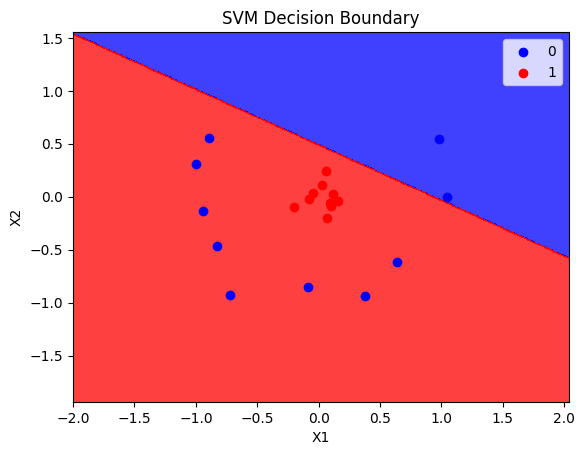

In [29]:
plot_decision_boundary(X_test, y_test, classifier)

In [30]:
def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax

<Axes3D: xlabel='X1', ylabel='X2', zlabel='y'>

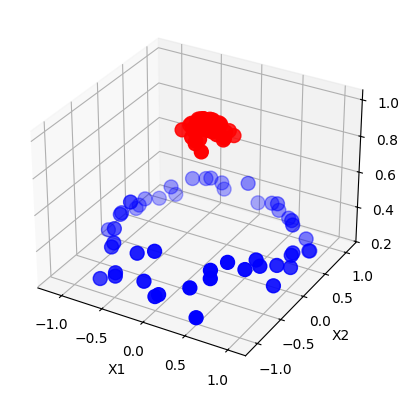

In [31]:
plot_3d_plot(X,y)

In [32]:
rbf_classifier = SVC(kernel="rbf")
rbf_classifier.fit(X_train, y_train)
y_pred = rbf_classifier.predict(X_test)

In [33]:
accuracy_score(y_test, y_pred)


1.0

C:\Users\Snehal\AppData\Local\Temp\ipykernel_26164\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


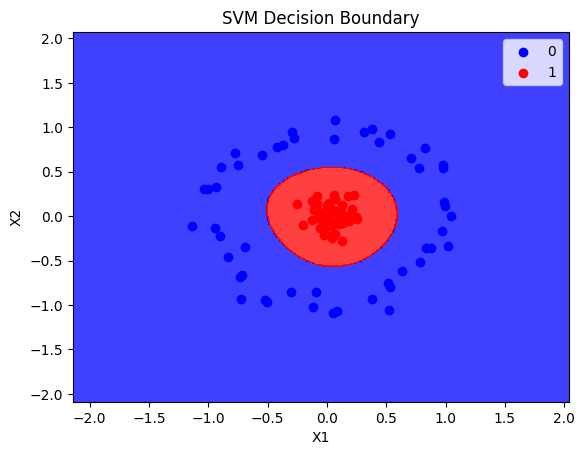

In [34]:
plot_decision_boundary(X, y, rbf_classifier)


In [35]:
poly_classifier = SVC(kernel="poly",degree=2)
poly_classifier.fit(X_train, y_train)
y_pred = poly_classifier.predict(X_test)

In [36]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\Snehal\AppData\Local\Temp\ipykernel_26164\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


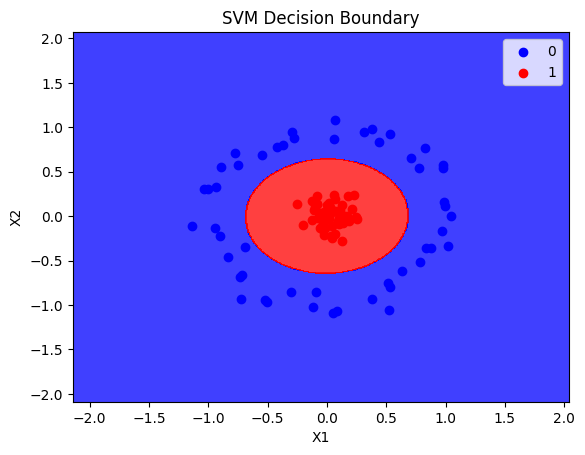

In [37]:
plot_decision_boundary(X, y, poly_classifier)

In [38]:
X

array([[ 1.17210608e-01,  2.55665158e-02],
       [-5.45085372e-01,  6.92469553e-01],
       [ 1.24446332e-01,  1.20990280e-01],
       [ 6.17264022e-02,  2.39552086e-01],
       [ 1.75470837e-01,  2.20919630e-01],
       [-7.20961408e-01, -9.28205389e-01],
       [-8.99083344e-02, -8.55478870e-01],
       [-9.45101955e-01, -1.35631445e-01],
       [ 1.83300718e-01, -5.87854873e-02],
       [-1.28348712e-01,  1.66152542e-01],
       [ 3.46356827e-02, -2.28967299e-01],
       [-1.08675155e-01,  6.71153725e-02],
       [ 9.30489580e-04,  1.21236624e-01],
       [ 8.29784434e-01,  7.71638643e-01],
       [-7.48110020e-02, -2.20477724e-02],
       [ 9.76753662e-01,  5.73726206e-01],
       [ 1.89564897e-02, -3.02733675e-02],
       [ 1.02345609e+00, -3.33965767e-01],
       [-2.54409203e-01,  1.40838626e-01],
       [-8.57907334e-02,  1.31453393e-01],
       [-9.02915257e-01, -2.28069182e-01],
       [ 3.82688089e-01,  9.77218050e-01],
       [ 1.91360816e-02,  1.52321303e-01],
       [ 9.

In [43]:
X_new=np.exp(-(X**2))


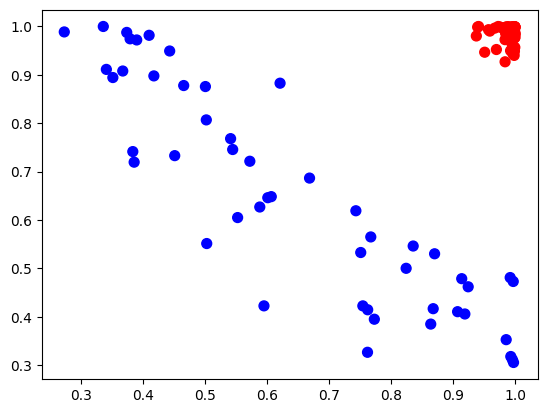

In [44]:
plt.scatter(X_new[:, 0], X_new[:, 1], c=y, s=50, cmap='bwr')